# Stage 11: Explainable AI with SHAP
Lenders must be able to explain *why* an applicant was declined. US Regulation B requires specific "principal reasons" for
adverse action, and the EU AI Act treats credit scoring as high-risk. Model-risk reviewers also want to see that the
model relies on sensible drivers.

**SHAP** (SHapley Additive exPlanations) splits each prediction into additive contributions, one per feature:
`model output = base value + Σ SHAP values`. For tree models, `TreeExplainer` computes them exactly and quickly.

This notebook covers:
1. **Global** importance: which features drive risk overall
2. **Direction and shape** of effects (beeswarm, dependence plots)
3. **Local** explanations for individual applicants → reason codes

*Technical note:* SHAP values are in log-odds of the underlying model. Our Platt calibration is a monotonic transformation
of that score, so the direction and ranking of each feature's contribution carry over to the calibrated PD.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from credit_risk.artifacts import load_final_model, load_split_frames
from credit_risk.config import get_paths, load_config
from credit_risk.explainability import get_explainer, global_importance, label, reason_codes, shap_values
from credit_risk.thresholds import assign_decision, load_policy
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ID, TARGET = cfg["data"]["id_column"], cfg["data"]["target"]

train, valid, test = load_split_frames(paths)
model = load_final_model(paths)
policy = load_policy(paths["models"] / "decision_policy.json")
print(f"Explaining: {model.name}")

N_EXPLAIN = min(3000, len(test))
sample = test.sample(N_EXPLAIN, random_state=0).reset_index(drop=True)
explainer = get_explainer(model, background=train.sample(min(1000, len(train)), random_state=0))
exp = shap_values(model, sample, explainer)
exp_display = shap.Explanation(values=exp.values, base_values=exp.base_values, data=exp.data,
                               feature_names=[label(f) for f in exp.feature_names])
print(f"SHAP matrix: {exp.values.shape}")

Explaining: lightgbm
SHAP matrix: (3000, 200)


## 1. Global feature importance (mean |SHAP|)

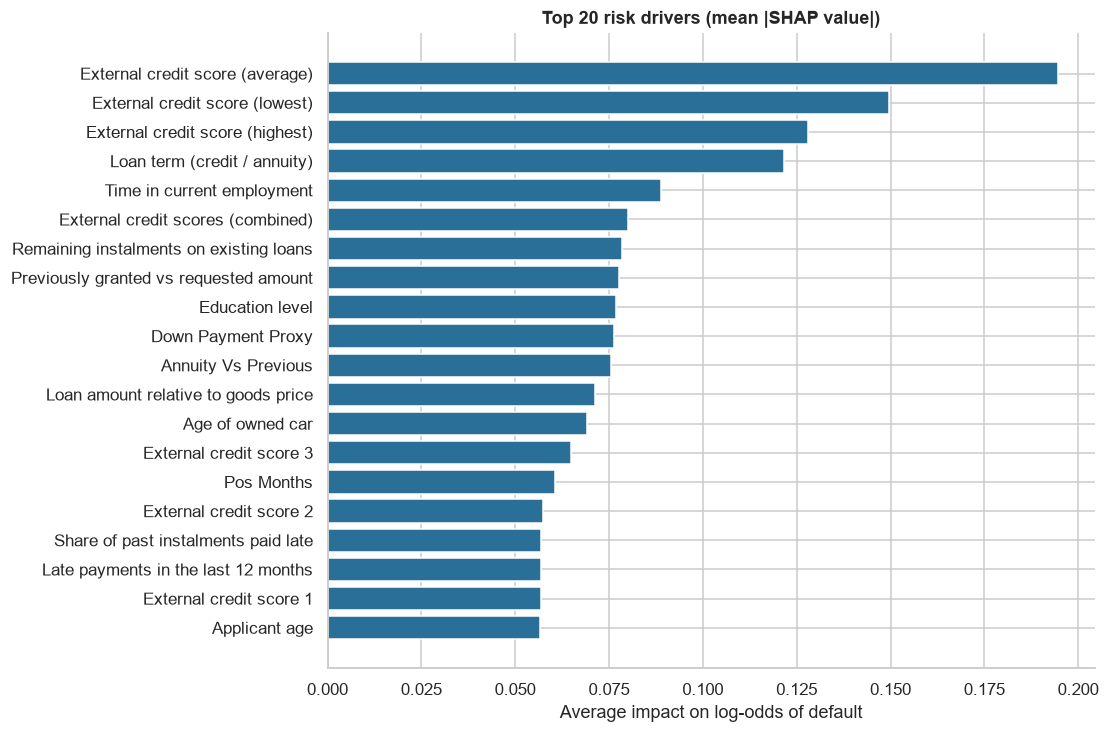

,feature,label,mean_abs_shap,share_pct
0,EXT_SOURCE_MEAN,External credit score (average),0.1947,5.2209
1,EXT_SOURCE_MIN,External credit score (lowest),0.1496,4.0118
2,EXT_SOURCE_MAX,External credit score (highest),0.1280,3.4314
3,CREDIT_TO_ANNUITY_RATIO,Loan term (credit / annuity),0.1215,3.2585
4,YEARS_EMPLOYED,Time in current employment,0.0888,2.3825
5,EXT_SOURCE_PROD,External credit scores (combined),0.0800,2.1459
6,POS_REMAINING_INSTALMENTS_SUM,Remaining instalments on existing loans,0.0784,2.1014
7,PREV_CREDIT_TO_APPLICATION_MEAN,Previously granted vs requested amount,0.0777,2.0843
8,NAME_EDUCATION_TYPE,Education level,0.0768,2.0603
9,DOWN_PAYMENT_PROXY,Down Payment Proxy,0.0763,2.0462


In [2]:
imp = global_importance(exp)
fig, ax = plt.subplots(figsize=(9, 7.5))
top = imp.head(20)[::-1]
ax.barh(top["label"], top["mean_abs_shap"], color=COLORS["good"])
ax.set(title="Top 20 risk drivers (mean |SHAP value|)", xlabel="Average impact on log-odds of default")
savefig(fig, "shap_global_importance")
plt.show()
imp.head(20)[["feature", "label", "mean_abs_shap", "share_pct"]].round(4)

In [3]:
by_source = imp.assign(source=imp["feature"].str.extract(r"^(BUREAU|PREV|INST|POS|CC)_")[0].fillna("APPLICATION"))
by_source.groupby("source")["share_pct"].sum().sort_values(ascending=False).round(1).to_frame("share_of_total_importance_%")

,share_of_total_importance_%
source,
APPLICATION,57.9
BUREAU,14.3
INST,9.6
PREV,9.4
POS,5.2
CC,3.6


## 2. Direction of effects: beeswarm
Each dot is one applicant. Position = impact on risk (right = riskier), colour = the feature's value (red = high).

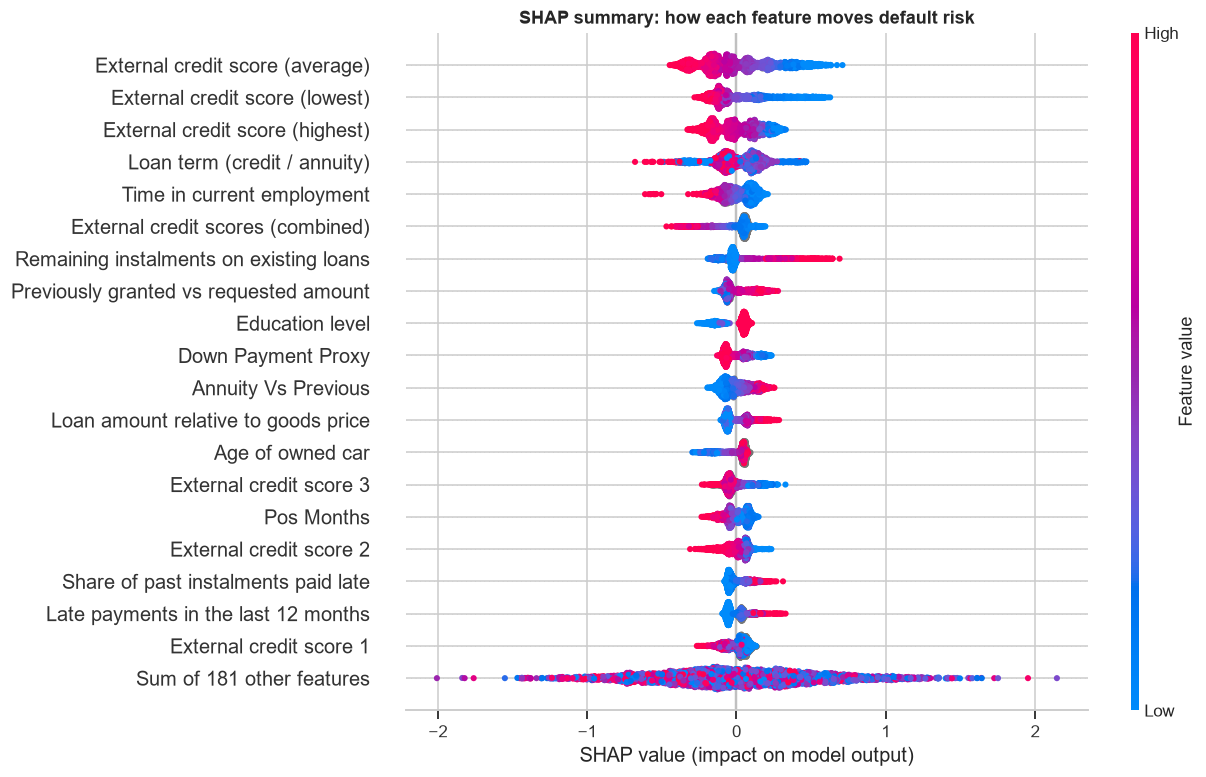

In [4]:
plt.figure()
shap.plots.beeswarm(exp_display, max_display=20, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 8)
plt.title("SHAP summary: how each feature moves default risk")
savefig(fig, "shap_beeswarm")
plt.show()

## 3. Shape of effects: dependence plots for the top drivers
These answer "is the relationship monotonic and sensible?", a standard model-validation question.
For example, risk should *fall* as external scores rise and *rise* with the share of late payments.

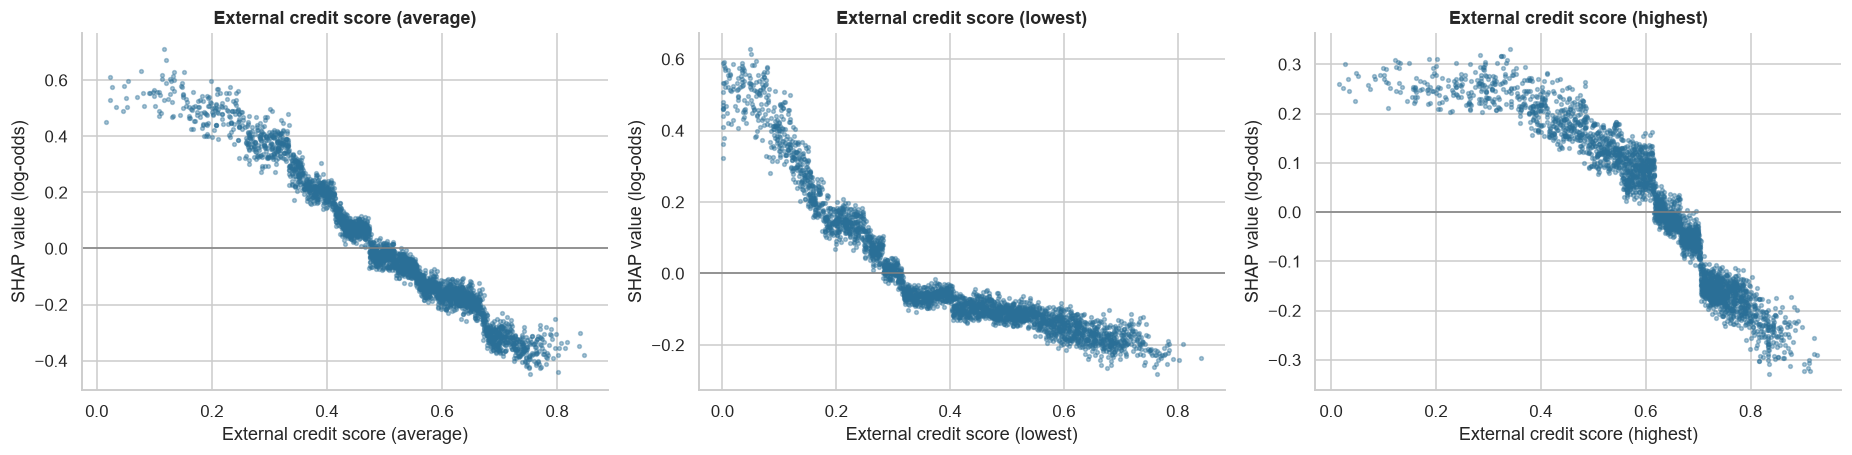

In [5]:
top3 = imp["feature"].head(3).tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for ax, f in zip(axes, top3):
    j = exp.feature_names.index(f)
    x = exp.data[:, j].astype(float)
    ax.scatter(x, exp.values[:, j], s=6, alpha=0.4, color=COLORS["good"])
    ax.axhline(0, color="grey", lw=1)
    ax.set(xlabel=label(f), ylabel="SHAP value (log-odds)", title=label(f))
fig.tight_layout()
savefig(fig, "shap_dependence_top3")
plt.show()

## 4. Local explanations: why *this* applicant?
We pick three real test applicants: a clear **decline**, a **borderline** case and a clear **approve**.

In [6]:
sample_pd = model.predict_pd(sample)
sample_dec = assign_decision(sample_pd, policy)
picks = {
    "Decline": int(np.argmax(sample_pd)),
    "Borderline (refer)": int(np.argmin(np.abs(sample_pd - policy["decline_at_or_above"]))),
    "Approve": int(np.argmin(sample_pd)),
}
pd.DataFrame([{"case": k, ID: sample.loc[i, ID], "PD": sample_pd[i], "decision": sample_dec[i], "actual_TARGET": sample.loc[i, TARGET]}
              for k, i in picks.items()]).round(4)

,case,SK_ID_CURR,PD,decision,actual_TARGET
0,Decline,372475,0.6343,Decline,1
1,Borderline (refer),425548,0.2101,Decline,1
2,Approve,241487,0.0008,Approve,0


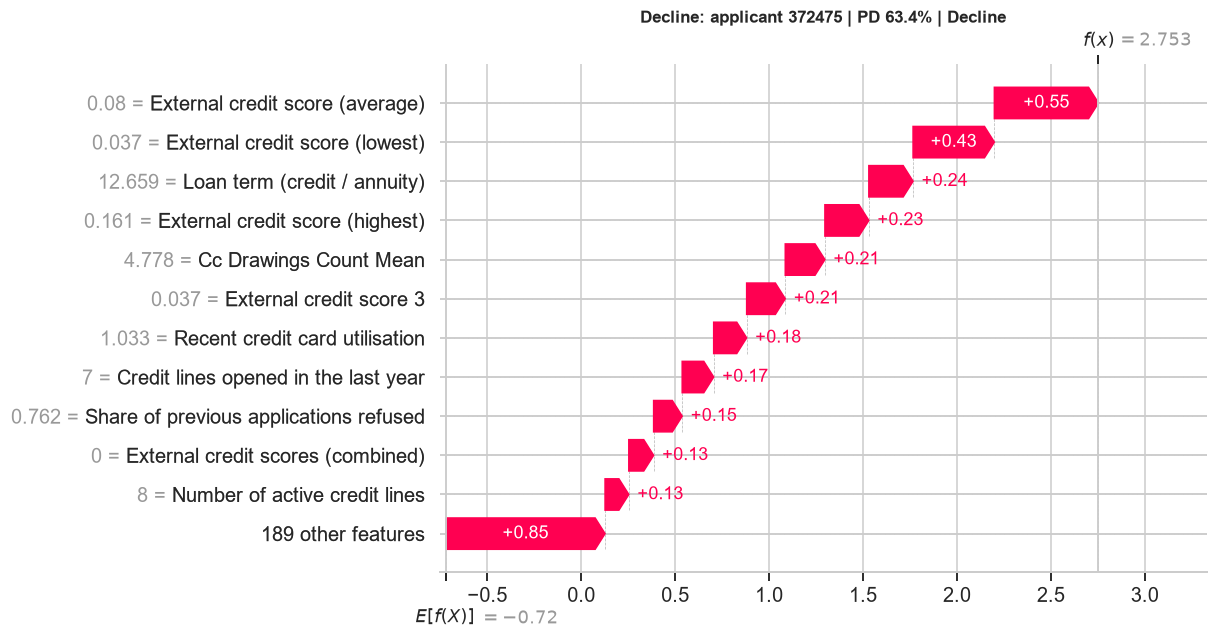

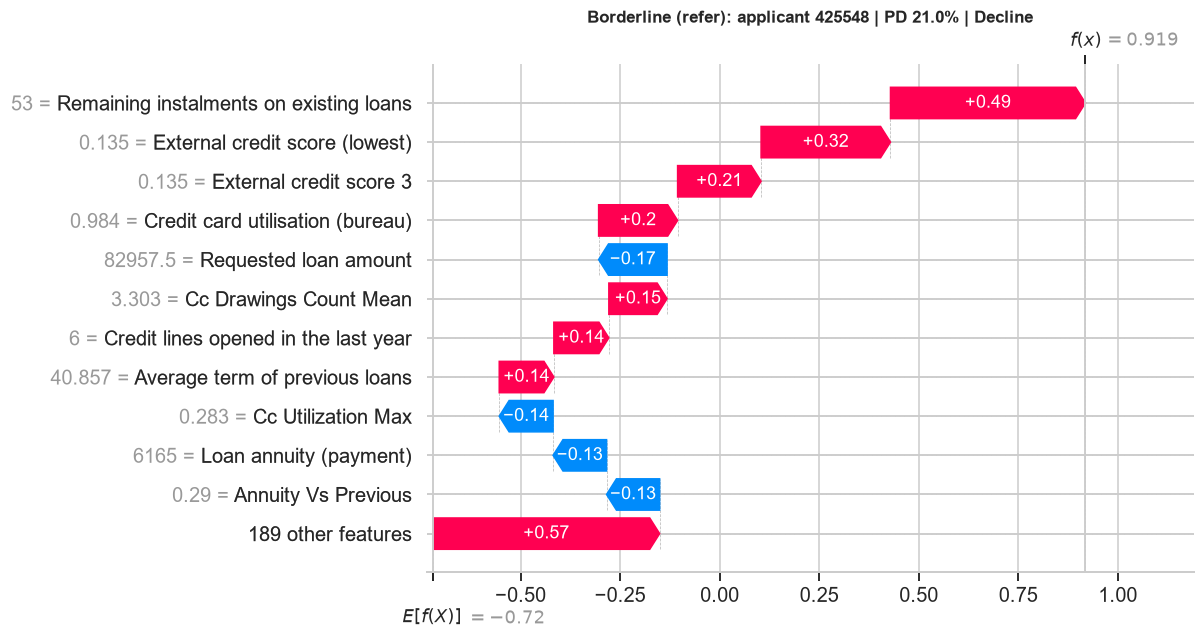

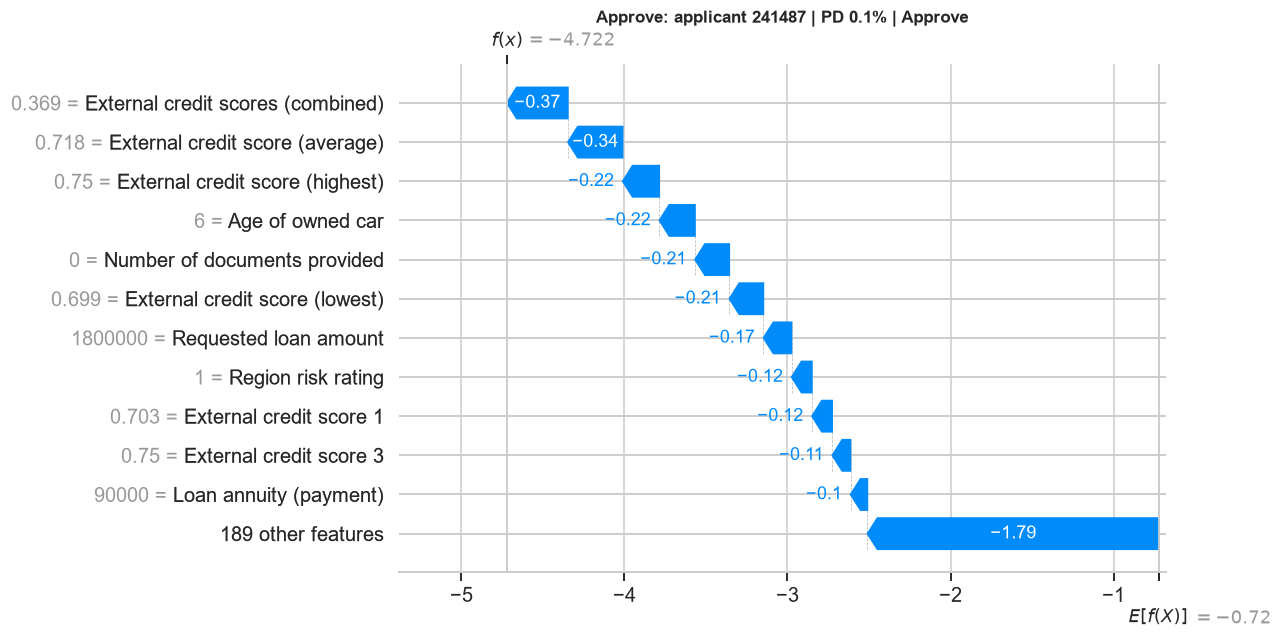

In [7]:
for case, i in picks.items():
    plt.figure()
    shap.plots.waterfall(exp_display[i], max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 6)
    plt.title(f"{case}: applicant {sample.loc[i, ID]} | PD {sample_pd[i]:.1%} | {sample_dec[i]}", fontsize=11)
    savefig(fig, f"shap_waterfall_{case.split()[0].lower()}")
    plt.show()

## 5. Reason codes (adverse-action style)
For a declined applicant, the top features *increasing* risk become the stated reasons, in plain language.

In [8]:
i = picks["Decline"]
codes = reason_codes(exp[i], top_n=4, raw_values=sample.iloc[i])
print(f"Applicant {sample.loc[i, ID]}: PD {sample_pd[i]:.1%} -> {sample_dec[i]}\n")
print("Principal reasons for the decision:")
for k, r in enumerate(codes[codes["shap"] > 0].itertuples(), 1):
    v = r.value
    vtxt = "missing" if pd.isna(v) else (f"{v:,.3f}" if isinstance(v, (float, np.floating)) else str(v))
    print(f"  {k}. {r.label} (value: {vtxt})")
codes.round(4)

Applicant 372475: PD 63.4% -> Decline

Principal reasons for the decision:
  1. External credit score (average) (value: 0.080)
  2. External credit score (lowest) (value: 0.037)
  3. Loan term (credit / annuity) (value: 12.659)
  4. External credit score (highest) (value: 0.161)


,feature,shap,model_value,label,value,direction
0,EXT_SOURCE_MEAN,0.5542,0.0804,External credit score (average),0.080411,Increases risk
1,EXT_SOURCE_MIN,0.4327,0.0369,External credit score (lowest),0.036862,Increases risk
2,CREDIT_TO_ANNUITY_RATIO,0.2354,12.6594,Loan term (credit / annuity),12.65936,Increases risk
3,EXT_SOURCE_MAX,0.2339,0.1605,External credit score (highest),0.160509,Increases risk
4,ANNUITY_VS_PREVIOUS,-0.0788,0.8169,Annuity Vs Previous,0.816949,Decreases risk
5,YEARS_EMPLOYED,-0.0741,12.5175,Time in current employment,12.517454,Decreases risk
6,PREV_CREDIT_TO_APPLICATION_MEAN,-0.0542,0.9667,Previously granted vs requested amount,0.966683,Decreases risk
7,EMPLOYED_TO_AGE_RATIO,-0.0449,0.3265,Share of adult life employed,0.326548,Decreases risk


**Production caveats for reason codes**
- Customer-facing reasons must be understandable and *actionable* ("high existing debt relative to income"), never
  "EXT_SOURCE_3". Keep the mapping table in `credit_risk.explainability.FEATURE_LABELS` reviewed by compliance.
- Opaque third-party scores (`EXT_SOURCE_*`) are a common reason code here. A real lender would have to be able to explain them too.
- Features that proxy protected characteristics should never appear as a stated reason.

In [9]:
imp.to_csv(paths["reports"] / "shap_global_importance.csv", index=False)
print("Saved reports/shap_global_importance.csv and SHAP figures.")

Saved reports/shap_global_importance.csv and SHAP figures.
